In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
users_df = pd.read_csv("users_cleaned_dataset.csv")
fusers_df = pd.read_csv("fusers_cleaned_dataset.csv")

# Combined data
combined_df = pd.concat([users_df, fusers_df])
combined_df

,id,username,name,account_created_at,bio,bio_length,num_posts,followers_count,following_count,username_length,num_digits_username,digit_ratio_username,followers_following_ratio,fake
0,1,braddd,Davide Dellacasa,2007-04-06 10:58:22+00:00,Founder of http://www.screenweek.it & http://w...,151,20370,5470,2385,6,0,0.0,2.29,0
1,2,eKoeS,Simone Economo,2007-04-30 15:08:42+00:00,BSc degree (cum laude) in Computer Engineering...,104,3131,506,381,5,0,0.0,1.33,0
2,3,tacone_,tacone,2007-05-01 11:53:40+00:00,Cogito ergo bestemmio.,22,4024,264,87,7,0,0.0,3.03,0
3,4,alesstar,alesaura,2007-05-15 16:55:16+00:00,"Se la vita ti dà sarde, scapocciale!",36,40586,640,622,8,0,0.0,1.03,0
4,5,PerDiletto,Angelo,2007-05-13 19:52:00+00:00,Je me souviens,14,2016,62,64,10,0,0.0,0.97,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7334,7335,byroamnh,Byron Ma,2014-04-14 15:06:29,"Tech , music and lover. Leading publishing ...",96,107,13,1482,8,0,0.0,0.01,1
7335,7336,northwindsavhc,Barb,2015-05-02 13:09:37,"North Winds Heating & , Inc. has provided prec...",127,2369,40,967,14,0,0.0,0.04,1
7336,7337,Since_Thereoerf,The Space of,2014-05-10 01:54:51,"Stand-Up Philosopher, Author, Writer, , Artist...",87,11,19,447,15,0,0.0,0.04,1
7337,7338,TheSOILSotre,Shop,2015-06-12 15:33:30,We are your #1 choice for all your landscaping...,113,0,9,680,12,0,0.0,0.01,1


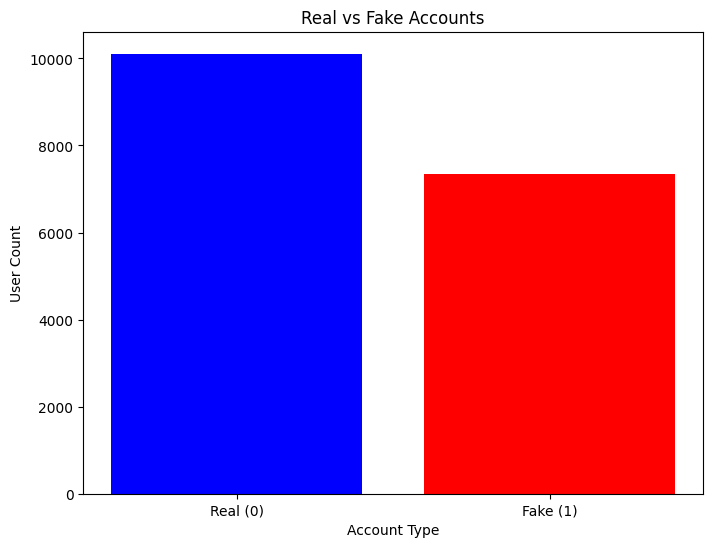

In [3]:
# 1. Bar Chart
# Count
user_counts = combined_df['fake'].value_counts()

# Bar Chart
plt.figure(figsize=(8,6))
plt.bar(['Real (0)', 'Fake (1)'], [user_counts[0], user_counts[1]], color = ['blue', 'red'])
plt.xlabel('Account Type')
plt.ylabel('User Count')
plt.title('Real vs Fake Accounts')

plt.show()

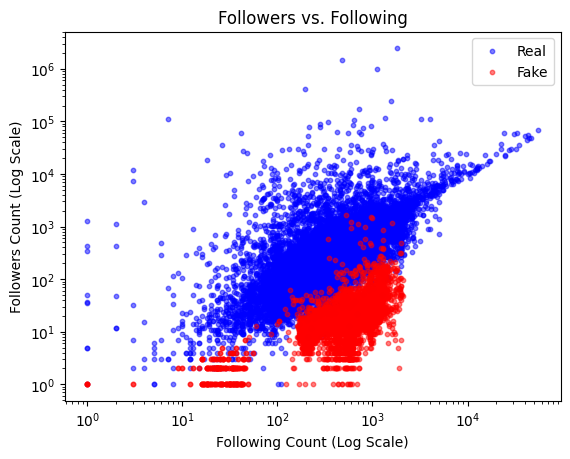

In [5]:
# 2. Scatter Plot
followers = combined_df['followers_count'] + 1     # adding 1 to avoid log(0) errors
following = combined_df['following_count'] + 1
labels = combined_df['fake']

plt.scatter(following[labels == 0], followers[labels == 0], 
            color='blue', alpha=0.5, label='Real', s=10)
plt.scatter(following[labels == 1], followers[labels == 1], 
            color='red', alpha=0.5, label='Fake', s=10)

# Apply log scales
plt.xscale('log')
plt.yscale('log')

# Label
plt.xlabel('Following Count (Log Scale)')
plt.ylabel('Followers Count (Log Scale)')
plt.title('Followers vs. Following')
plt.legend()

plt.show()

In [5]:
digit_ratio_df = pd.DataFrame({
    "Real Accounts": users_df['digit_ratio_username'],
    "Fake Accounts": fusers_df['digit_ratio_username']
})

digit_ratio_df

,Real Accounts,Fake Accounts
0,0.000000,0.000000
1,0.000000,0.363636
2,0.000000,0.000000
3,0.000000,0.000000
4,0.000000,0.000000
...,...,...
10103,0.000000,NaN
10104,0.000000,NaN
10105,0.000000,NaN
10106,0.000000,NaN


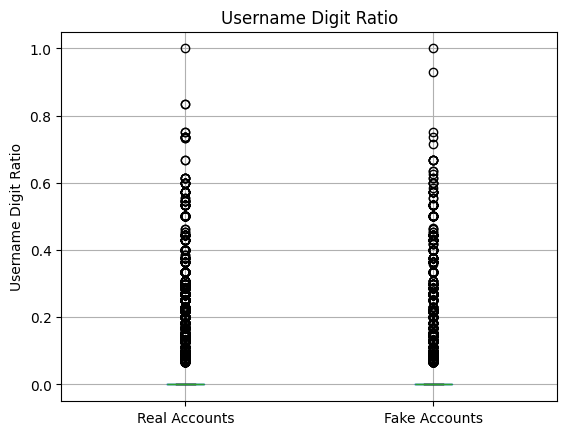

In [6]:
# 3. Box Plot
digit_ratio_df.boxplot()
plt.ylabel("Username Digit Ratio")
plt.title("Username Digit Ratio")
plt.show()

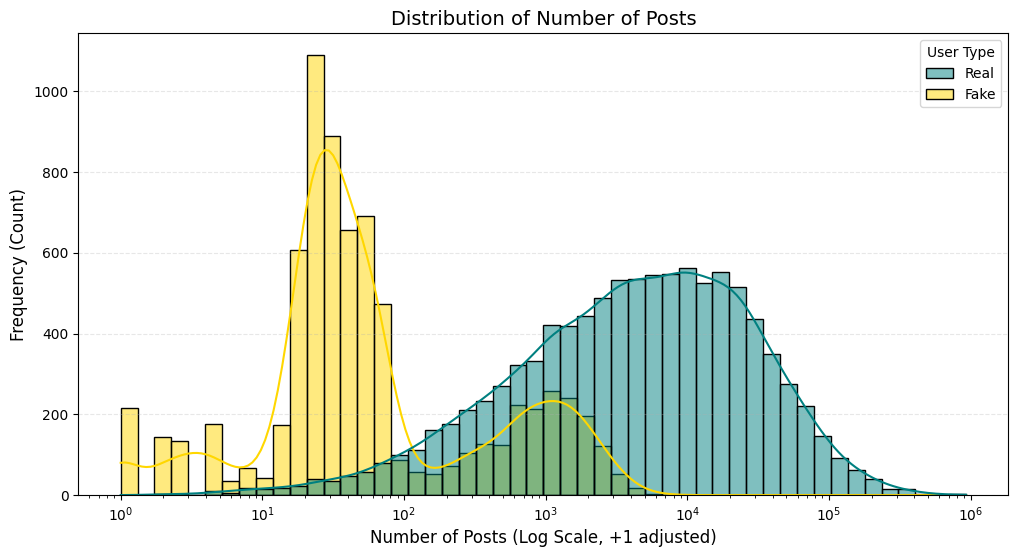

In [7]:
# 4. Histogram
users = pd.read_csv("users_cleaned_dataset.csv")
fusers = pd.read_csv("fusers_cleaned_dataset.csv")

fusers['User Type'] = 'Fake'
users['User Type'] = 'Real'

combined_df = pd.concat([users, fusers], ignore_index=True)

df_filtered = combined_df[combined_df['num_posts'] >= 0].copy()      #Filter out unknown (-1)

df_filtered['num_posts_log_adj'] = df_filtered['num_posts'] + 1

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df_filtered,
    x='num_posts_log_adj',
    hue = 'User Type',
    bins=50,
    kde=True,
    palette={'Real':'teal', 'Fake':'gold'},
    log_scale=True
)

plt.title('Distribution of Number of Posts', fontsize=14)
plt.xlabel('Number of Posts (Log Scale, +1 adjusted)', fontsize=12)
plt.ylabel('Frequency (Count)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()


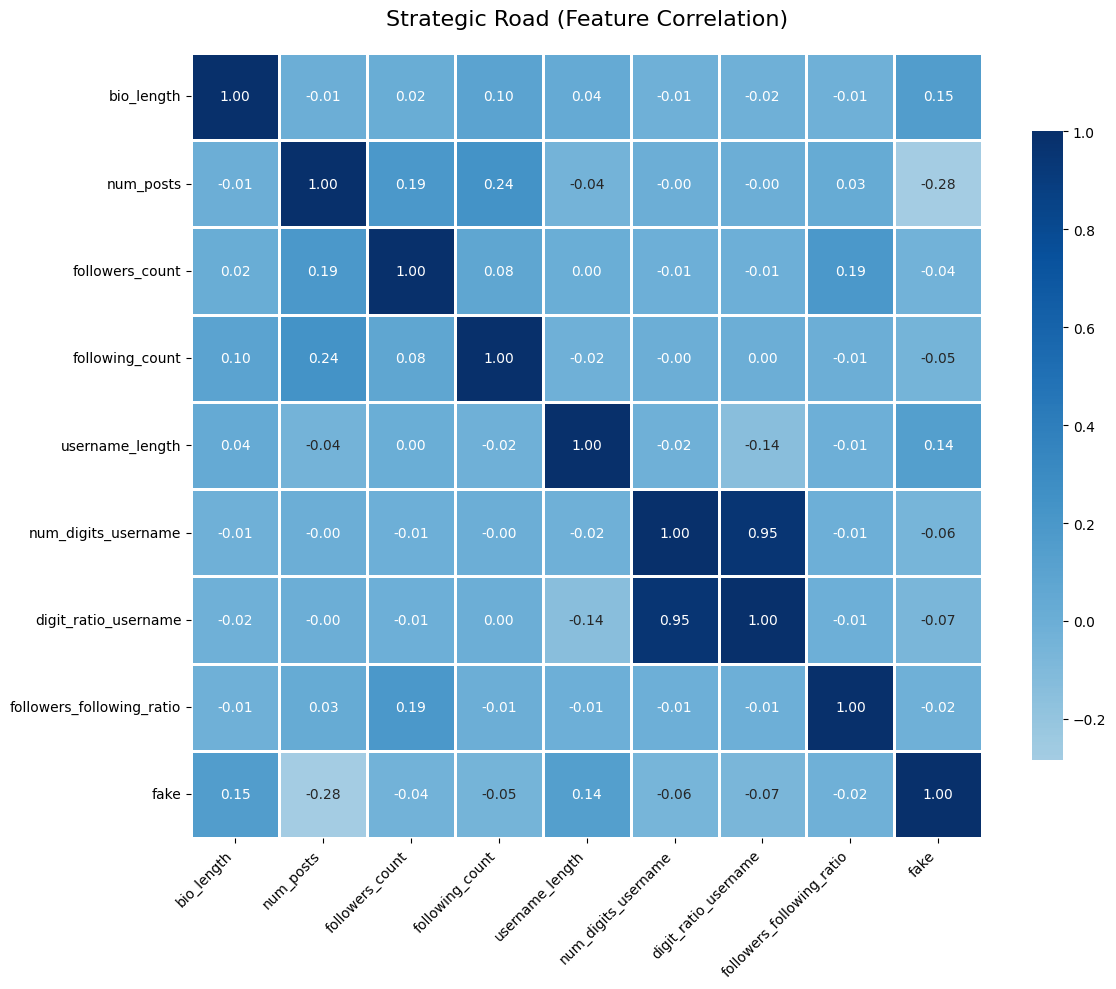

In [8]:
# 5. Heatmap
features = ['bio_length', 
            'num_posts', 
            'followers_count', 
            'following_count', 
            'username_length', 
            'num_digits_username', 
            'digit_ratio_username', 
            'followers_following_ratio', 
            'fake'
           ]

corr_df = combined_df[features].replace(-1, np.nan)   #Replace -1 (unknown) with NaN so they don't skew the correlation
corr_matrix = corr_df.corr()      #Calculate Peason correlation matrix

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    annot=True,
    fmt=".2f",
    cmap='Blues',
    center=0,
    linewidths=1,
    cbar_kws={"shrink": .8}
)

plt.title('Strategic Road (Feature Correlation)', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()